<a href="https://colab.research.google.com/github/ParthJirapure/a/blob/main/PBL(AQI).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
! unzip city_day.csv.zip

Archive:  city_day.csv.zip
  inflating: city_day.csv            


In [ ]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler, LabelEncoder

df = pd.read_csv('/content/city_day.csv')

df.fillna(df.mean(numeric_only=True), inplace=True)
df.drop_duplicates(inplace=True)

if 'date_column' in df.columns:
    df['date_column'] = pd.to_datetime(df['date_column'], errors='coerce')

if 'numeric_column' in df.columns:
    df['numeric_column'] = pd.to_numeric(df['numeric_column'], errors='coerce')

numeric_columns = ['numeric_column1', 'numeric_column2']
existing_numeric_columns = [col for col in numeric_columns if col in df.columns]

if existing_numeric_columns:
    scaler = MinMaxScaler()
    df[existing_numeric_columns] = scaler.fit_transform(df[existing_numeric_columns])

if 'category_column' in df.columns:
    label_encoder = LabelEncoder()
    df['category_column'] = label_encoder.fit_transform(df['category_column'])

if 'numeric_column' in df.columns:
    df_filtered = df[df['numeric_column'] > 10]
else:
    df_filtered = df.copy()

df_filtered.to_csv('cleaned_filtered_data.csv', index=False)

print(df_filtered.head())

        City        Date      PM2.5        PM10     NO    NO2    NOx  \
0  Ahmedabad  2015-01-01  67.450578  118.127103   0.92  18.22  17.15   
1  Ahmedabad  2015-01-02  67.450578  118.127103   0.97  15.69  16.46   
2  Ahmedabad  2015-01-03  67.450578  118.127103  17.40  19.30  29.70   
3  Ahmedabad  2015-01-04  67.450578  118.127103   1.70  18.48  17.97   
4  Ahmedabad  2015-01-05  67.450578  118.127103  22.10  21.42  37.76   

         NH3     CO    SO2      O3  Benzene  Toluene  Xylene         AQI  \
0  23.483476   0.92  27.64  133.36     0.00     0.02    0.00  166.463581   
1  23.483476   0.97  24.55   34.06     3.68     5.50    3.77  166.463581   
2  23.483476  17.40  29.07   30.70     6.80    16.40    2.25  166.463581   
3  23.483476   1.70  18.59   36.08     4.43    10.14    1.00  166.463581   
4  23.483476  22.10  39.33   39.31     7.01    18.89    2.78  166.463581   

  AQI_Bucket  
0        NaN  
1        NaN  
2        NaN  
3        NaN  
4        NaN  


In [ ]:
import pandas as pd
import numpy as np

file_path = "/content/cleaned_filtered_data.csv"
df = pd.read_csv(file_path)

if 'AQI_Bucket' in df.columns and 'AQI' in df.columns:
    conditions = [
        (df['AQI'] <= 50),
        (df['AQI'] > 50) & (df['AQI'] <= 100),
        (df['AQI'] > 100) & (df['AQI'] <= 200),
        (df['AQI'] > 200) & (df['AQI'] <= 300),
        (df['AQI'] > 300)
    ]

    choices = ['Good', 'Satisfactory', 'Moderate', 'Poor', 'Very Poor']

    df['AQI_Bucket'] = np.select(conditions, choices, default="Moderate")

output_path = "/content/cleaned_filtered_data.csv"
df.to_csv(output_path, index=False)

print(df.head())

        City        Date      PM2.5        PM10     NO    NO2    NOx  \
0  Ahmedabad  2015-01-01  67.450578  118.127103   0.92  18.22  17.15   
1  Ahmedabad  2015-01-02  67.450578  118.127103   0.97  15.69  16.46   
2  Ahmedabad  2015-01-03  67.450578  118.127103  17.40  19.30  29.70   
3  Ahmedabad  2015-01-04  67.450578  118.127103   1.70  18.48  17.97   
4  Ahmedabad  2015-01-05  67.450578  118.127103  22.10  21.42  37.76   

         NH3     CO    SO2      O3  Benzene  Toluene  Xylene         AQI  \
0  23.483476   0.92  27.64  133.36     0.00     0.02    0.00  166.463581   
1  23.483476   0.97  24.55   34.06     3.68     5.50    3.77  166.463581   
2  23.483476  17.40  29.07   30.70     6.80    16.40    2.25  166.463581   
3  23.483476   1.70  18.59   36.08     4.43    10.14    1.00  166.463581   
4  23.483476  22.10  39.33   39.31     7.01    18.89    2.78  166.463581   

  AQI_Bucket  
0   Moderate  
1   Moderate  
2   Moderate  
3   Moderate  
4   Moderate  


<ipython-input-4-d85cd585cefe>:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=aqi_distribution.index, y=aqi_distribution.values, palette="viridis")


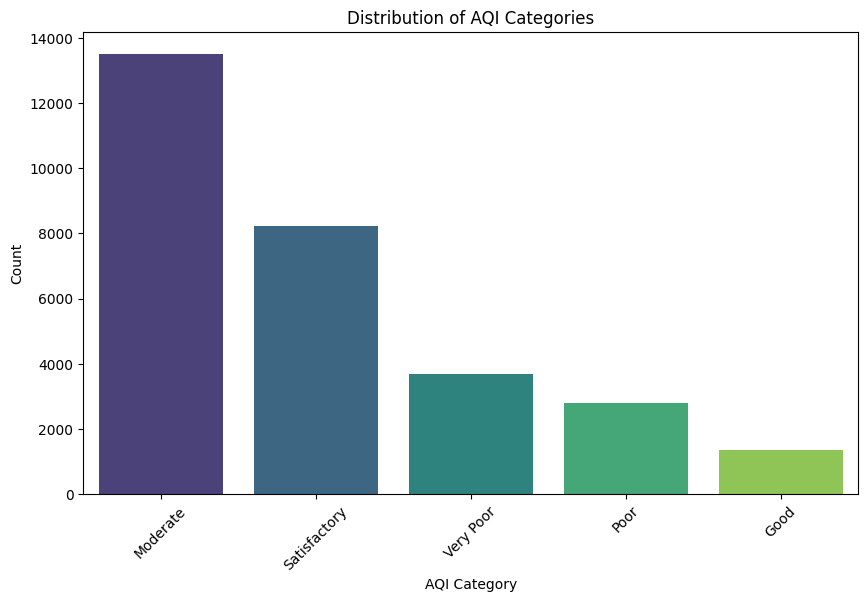

Category Distribution:
 AQI_Bucket
Moderate        13510
Satisfactory     8224
Very Poor        3675
Poor             2781
Good             1341
Name: count, dtype: int64


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

file_path = "/content/cleaned_filtered_data.csv"
df = pd.read_csv(file_path)
aqi_distribution = df["AQI_Bucket"].value_counts()
plt.figure(figsize=(10, 6))
sns.barplot(x=aqi_distribution.index, y=aqi_distribution.values, palette="viridis")
plt.xlabel("AQI Category")
plt.ylabel("Count")
plt.title("Distribution of AQI Categories")
plt.xticks(rotation=45)
plt.show()

print("Category Distribution:\n", aqi_distribution)

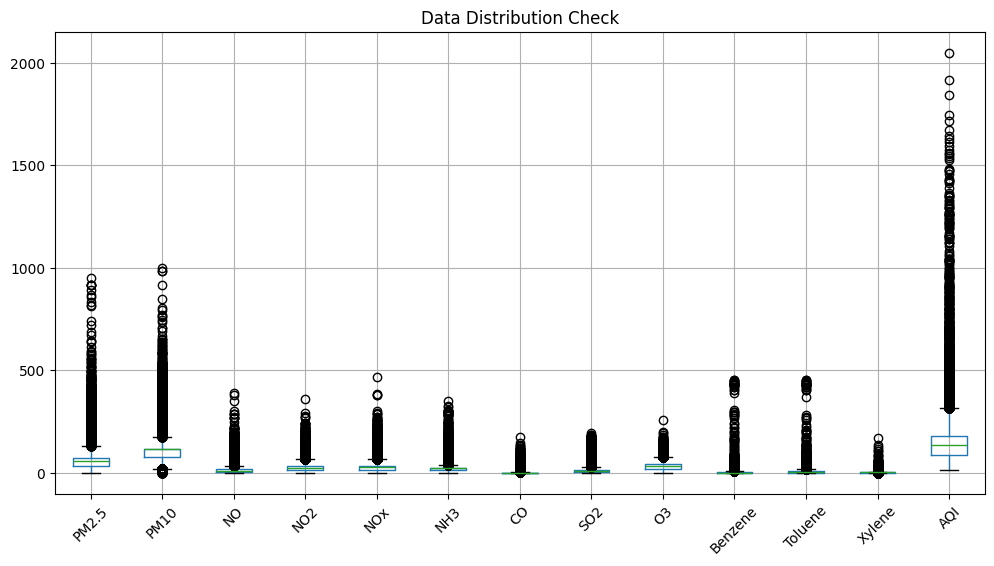

In [ ]:
import pandas as pd

df = pd.read_csv("/content/cleaned_filtered_data.csv")

numerical_cols = df.select_dtypes(include=['float64', 'int64']).columns

df[numerical_cols].describe().T[['mean', 'std']]

df[numerical_cols].describe().T[['min', 'max']]

df[numerical_cols].skew()

import matplotlib.pyplot as plt

df[numerical_cols].boxplot(figsize=(12,6), rot=45)
plt.title("Data Distribution Check")
plt.show()

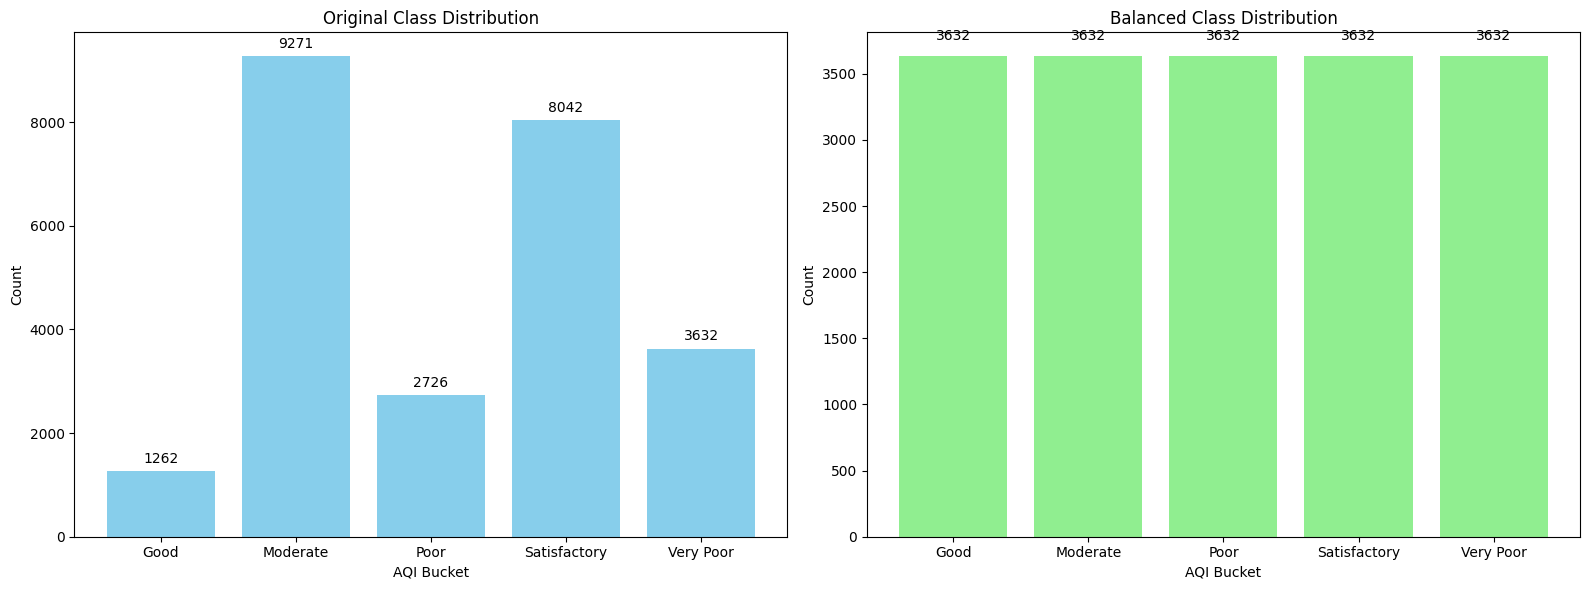

In [ ]:
import pandas as pd
from sklearn.utils import resample
import matplotlib.pyplot as plt

df = pd.read_csv('/content/cleaned_filtered_data.csv')

placeholder_pm25 = 67.45057794890306
clean_df = df[df['PM2.5'] != placeholder_pm25].copy()

original_counts = clean_df['AQI_Bucket'].value_counts()

df_majority = clean_df[clean_df['AQI_Bucket'] == 'Very Poor']
df_minority_good = clean_df[clean_df['AQI_Bucket'] == 'Good']
df_minority_satisfactory = clean_df[clean_df['AQI_Bucket'] == 'Satisfactory']
df_minority_moderate = clean_df[clean_df['AQI_Bucket'] == 'Moderate']
df_minority_poor = clean_df[clean_df['AQI_Bucket'] == 'Poor']

df_minority_good_upsampled = resample(df_minority_good, replace=True, n_samples=len(df_majority), random_state=42)
df_minority_satisfactory_upsampled = resample(df_minority_satisfactory, replace=True, n_samples=len(df_majority), random_state=42)
df_minority_moderate_upsampled = resample(df_minority_moderate, replace=True, n_samples=len(df_majority), random_state=42)
df_minority_poor_upsampled = resample(df_minority_poor, replace=True, n_samples=len(df_majority), random_state=42)

balanced_df = pd.concat([
    df_majority,
    df_minority_good_upsampled,
    df_minority_satisfactory_upsampled,
    df_minority_moderate_upsampled,
    df_minority_poor_upsampled
])

balanced_counts = balanced_df['AQI_Bucket'].value_counts()

fig, ax = plt.subplots(1, 2, figsize=(16, 6))

original_counts = original_counts.sort_index()
ax[0].bar(original_counts.index, original_counts.values, color='skyblue')
ax[0].set_title('Original Class Distribution')
ax[0].set_xlabel('AQI Bucket')
ax[0].set_ylabel('Count')
for i, val in enumerate(original_counts.values):
    ax[0].text(i, val + 100, str(val), ha='center', va='bottom', fontsize=10)

balanced_counts = balanced_counts.sort_index()
ax[1].bar(balanced_counts.index, balanced_counts.values, color='lightgreen')
ax[1].set_title('Balanced Class Distribution')
ax[1].set_xlabel('AQI Bucket')
ax[1].set_ylabel('Count')
for i, val in enumerate(balanced_counts.values):
    ax[1].text(i, val + 100, str(val), ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

balanced_df.to_csv('/content/cleaned_filtered_data.csv', index=False)

In [ ]:
#RF
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report

df = pd.read_csv("/content/cleaned_filtered_data.csv")
X = df.drop(columns=['City', 'Date', 'AQI', 'AQI_Bucket'])
y = df['AQI_Bucket']

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

value_counts = pd.Series(y_encoded).value_counts()
valid_classes = value_counts[value_counts > 1].index
mask = pd.Series(y_encoded).isin(valid_classes)
X = X[mask]
y_encoded = y_encoded[mask]

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

param_grid = {
    'n_estimators': [200],
    'max_depth': [20],
    'min_samples_split': [2],
    'min_samples_leaf': [1],
    'class_weight': ['balanced']
}

grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
grid.fit(X_train, y_train)

best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)

print(f"✅ Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")
print("📊 Classification Report (per AQI Bucket):\n")
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))

✅ Accuracy: 89.68%

📊 Classification Report (per AQI Bucket):

              precision    recall  f1-score   support

        Good       0.93      0.98      0.96       727
    Moderate       0.87      0.83      0.85       726
        Poor       0.85      0.94      0.89       726
Satisfactory       0.88      0.85      0.86       727
   Very Poor       0.97      0.88      0.92       726

    accuracy                           0.90      3632
   macro avg       0.90      0.90      0.90      3632
weighted avg       0.90      0.90      0.90      3632



In [ ]:
#XGBoost
import pandas as pd
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report

df = pd.read_csv("/content/cleaned_filtered_data.csv")
X = df.drop(columns=['City', 'Date', 'AQI', 'AQI_Bucket'])
y = df['AQI_Bucket']

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

value_counts = pd.Series(y_encoded).value_counts()
valid_classes = value_counts[value_counts > 1].index
mask = pd.Series(y_encoded).isin(valid_classes)
X = X[mask]
y_encoded = y_encoded[mask]

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

param_grid = {
    'n_estimators': [200],
    'max_depth': [6],
    'learning_rate': [0.1],
    'subsample': [0.8],
    'colsample_bytree': [0.8],
    'use_label_encoder': [False],
    'eval_metric': ['mlogloss']
}

grid = GridSearchCV(
    XGBClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
grid.fit(X_train, y_train)

best_model = grid.best_estimator_
y_pred = best_model.predict(X_test)

print(f"✅ Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")
print("📊 Classification Report (per AQI Bucket):\n")
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [17:08:02] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


✅ Accuracy: 88.30%

📊 Classification Report (per AQI Bucket):

              precision    recall  f1-score   support

        Good       0.92      0.98      0.95       727
    Moderate       0.85      0.80      0.83       726
        Poor       0.84      0.92      0.88       726
Satisfactory       0.86      0.83      0.84       727
   Very Poor       0.95      0.89      0.92       726

    accuracy                           0.88      3632
   macro avg       0.88      0.88      0.88      3632
weighted avg       0.88      0.88      0.88      3632



In [ ]:
#KNN
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

df = pd.read_csv("/content/cleaned_filtered_data.csv")

X = df.drop(columns=['City', 'Date', 'AQI', 'AQI_Bucket'])
y = df['AQI_Bucket']

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

value_counts = pd.Series(y_encoded).value_counts()
valid_classes = value_counts[value_counts > 1].index
mask = pd.Series(y_encoded).isin(valid_classes)
X = X[mask]
y_encoded = y_encoded[mask]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

param_grid = {
    'n_neighbors': [3, 5, 7],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean']
}

print("⏳ Tuning hyperparameters...")
grid = GridSearchCV(KNeighborsClassifier(), param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid.fit(X_train, y_train)

best_knn = grid.best_estimator_
y_pred = best_knn.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred, target_names=label_encoder.classes_)

print(f"\n✅ Accuracy: {accuracy * 100:.2f}%")
print("\n📊 Classification Report (per AQI Bucket):\n")
print(report)


⏳ Tuning hyperparameters...

✅ Accuracy: 85.52%

📊 Classification Report (per AQI Bucket):

              precision    recall  f1-score   support

        Good       0.88      0.99      0.94       727
    Moderate       0.87      0.71      0.78       726
        Poor       0.79      0.93      0.85       726
Satisfactory       0.81      0.80      0.80       727
   Very Poor       0.94      0.85      0.90       726

    accuracy                           0.86      3632
   macro avg       0.86      0.86      0.85      3632
weighted avg       0.86      0.86      0.85      3632



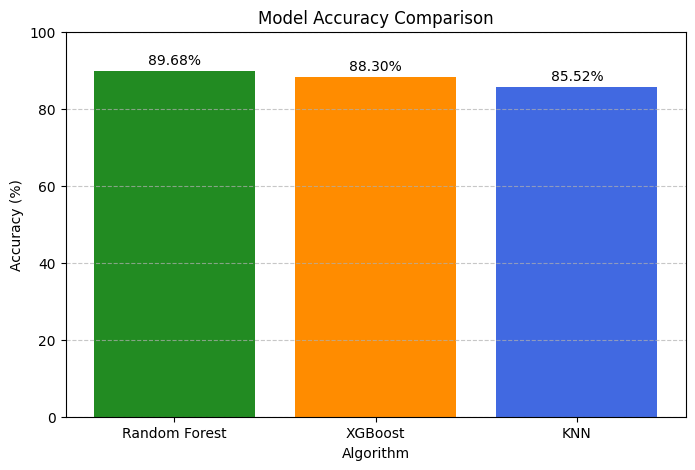

In [ ]:
import matplotlib.pyplot as plt

models = ['Random Forest', 'XGBoost', 'KNN']
accuracies = [89.68, 88.30, 85.52]

plt.figure(figsize=(8, 5))
plt.bar(models, accuracies, color=['forestgreen', 'darkorange', 'royalblue'])
plt.ylim(0, 100)
plt.xlabel('Algorithm')
plt.ylabel('Accuracy (%)')
plt.title('Model Accuracy Comparison')
plt.grid(axis='y', linestyle='--', alpha=0.7)

for i, acc in enumerate(accuracies):
    plt.text(i, acc + 1, f"{acc:.2f}%", ha='center', va='bottom', fontsize=10)

plt.show()